<a href="https://colab.research.google.com/github/lavanyalagudu16-commits/2520090009_deeplearning/blob/2520090009_skill/skill5(deeplen).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pycocotools matplotlib opencv-python

In [2]:
import os
import json
import cv2
import matplotlib.pyplot as plt

from google.colab import files
from pycocotools.coco import COCO

In [3]:
uploaded = files.upload()

Saving IndianTraffic.v1-v-1.coco.zip to IndianTraffic.v1-v-1.coco.zip


In [4]:
import zipfile

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/traffic_dataset')

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [9]:
annotation_path = "/content/traffic_dataset/annotations/instances.json"

coco = COCO(annotation_path)

print("COCO annotations loaded successfully!")

Found annotation file: /content/traffic_dataset/train/_annotations.coco.json
loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
COCO annotations loaded successfully!


In [7]:
import os

def list_files(startpath):
    for root, dirs, files in os.walk(startpath):
        level = root.replace(startpath, '').count(os.sep)
        indent = ' ' * 4 * (level)
        print(f'{indent}{os.path.basename(root)}/')
        subindent = ' ' * 4 * (level + 1)
        for f in files[:5]: # Limit to 5 files per directory for readability
            print(f'{subindent}{f}')

list_files('/content/traffic_dataset')

traffic_dataset/
    README.roboflow.txt
    README.dataset.txt
    train/
        img_00108_jpg.rf.6b3f16d1be53077526f9a1a0bf94b6c7.jpg
        img_00162_jpg.rf.b8da57540733e3a8a9ec60b524214819.jpg
        img_00051_jpg.rf.34f0ec9bcd8c5bd2b0711208a832fa04.jpg
        img_00031_jpg.rf.55245d9e9082a897339c7777e25f786d.jpg
        img_00170_jpg.rf.faacd48374a2b31ab45937a39cfe229f.jpg


In [10]:
categories = coco.loadCats(coco.getCatIds())

print("Object Categories:")

for category in categories:
    print(category['id'], ":", category['name'])

Object Categories:
0 : objects
1 : 2-Wheeler
2 : 3-Wheeler
3 : Bus
4 : Hatchback
5 : LCV
6 : MUV
7 : SUV
8 : Sedan
9 : T- Traveller -Tempo-traveller-
10 : Truck
11 : Van


In [11]:
image_ids = coco.getImgIds()
annotation_ids = coco.getAnnIds()

print("Total Images:", len(image_ids))
print("Total Annotations:", len(annotation_ids))
print("Total Categories:", len(categories))

Total Images: 531
Total Annotations: 18264
Total Categories: 12


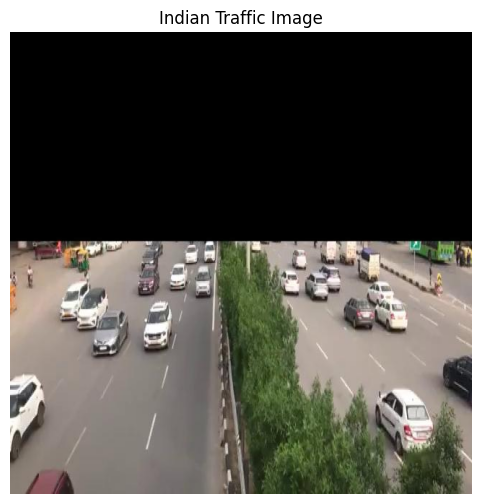

In [12]:
image_id = image_ids[0]

image_info = coco.loadImgs(image_id)[0]

image_path = os.path.join(
    "/content/traffic_dataset/images",
    image_info['file_name']
)

image = cv2.imread(image_path)

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(image)
plt.title("Indian Traffic Image")
plt.axis("off")
plt.show()

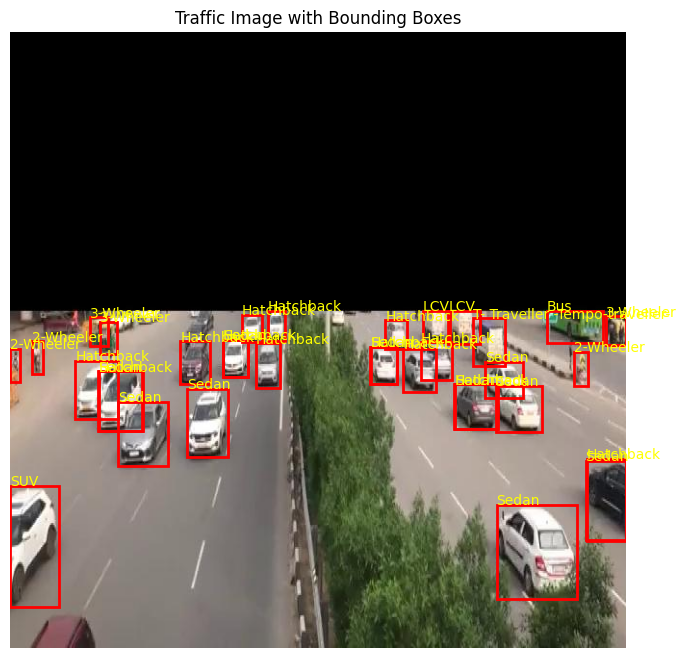

In [13]:
image_id = image_ids[0]

image_info = coco.loadImgs(image_id)[0]

image_path = os.path.join(
    "/content/traffic_dataset/images",
    image_info['file_name']
)

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

annotation_ids = coco.getAnnIds(imgIds=[image_id])
annotations = coco.loadAnns(annotation_ids)

plt.figure(figsize=(12, 8))
plt.imshow(image)

for ann in annotations:

    x, y, w, h = ann['bbox']

    plt.gca().add_patch(
        plt.Rectangle(
            (x, y),
            w,
            h,
            fill=False,
            edgecolor='red',
            linewidth=2
        )
    )

    category = coco.loadCats([ann['category_id']])[0]['name']

    plt.text(x, y, category, color='yellow', fontsize=10)

plt.title("Traffic Image with Bounding Boxes")
plt.axis("off")
plt.show()

In [14]:
from collections import Counter

category_counts = Counter()

for ann_id in coco.getAnnIds():
    ann = coco.loadAnns([ann_id])[0]

    category = coco.loadCats([ann['category_id']])[0]['name']

    category_counts[category] += 1

for name, count in category_counts.items():
    print(name, ":", count)

Sedan : 3030
2-Wheeler : 4342
3-Wheeler : 1733
Hatchback : 6313
Bus : 717
SUV : 762
LCV : 352
T- Traveller -Tempo-traveller- : 145
MUV : 693
Van : 104
Truck : 73


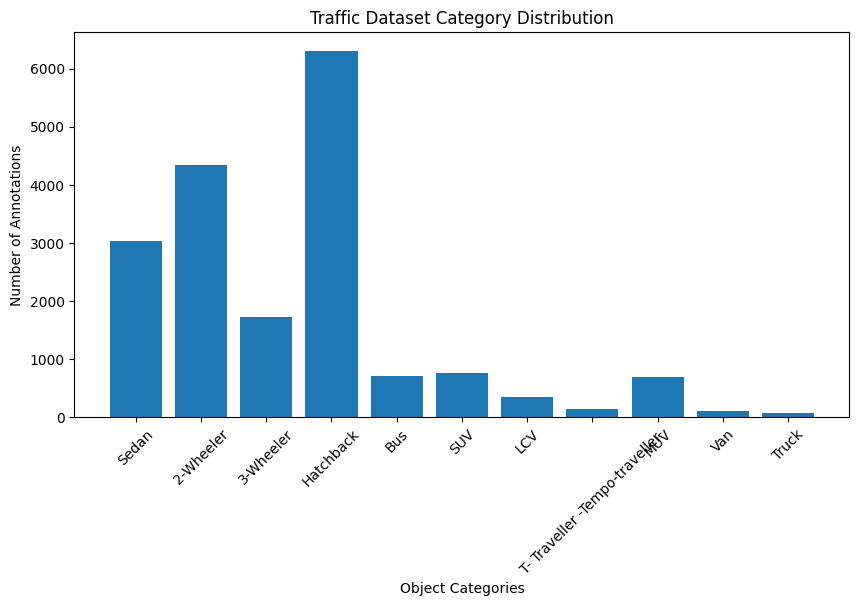

In [15]:
plt.figure(figsize=(10, 5))

plt.bar(
    category_counts.keys(),
    category_counts.values()
)

plt.xlabel("Object Categories")
plt.ylabel("Number of Annotations")
plt.title("Traffic Dataset Category Distribution")

plt.xticks(rotation=45)
plt.show()

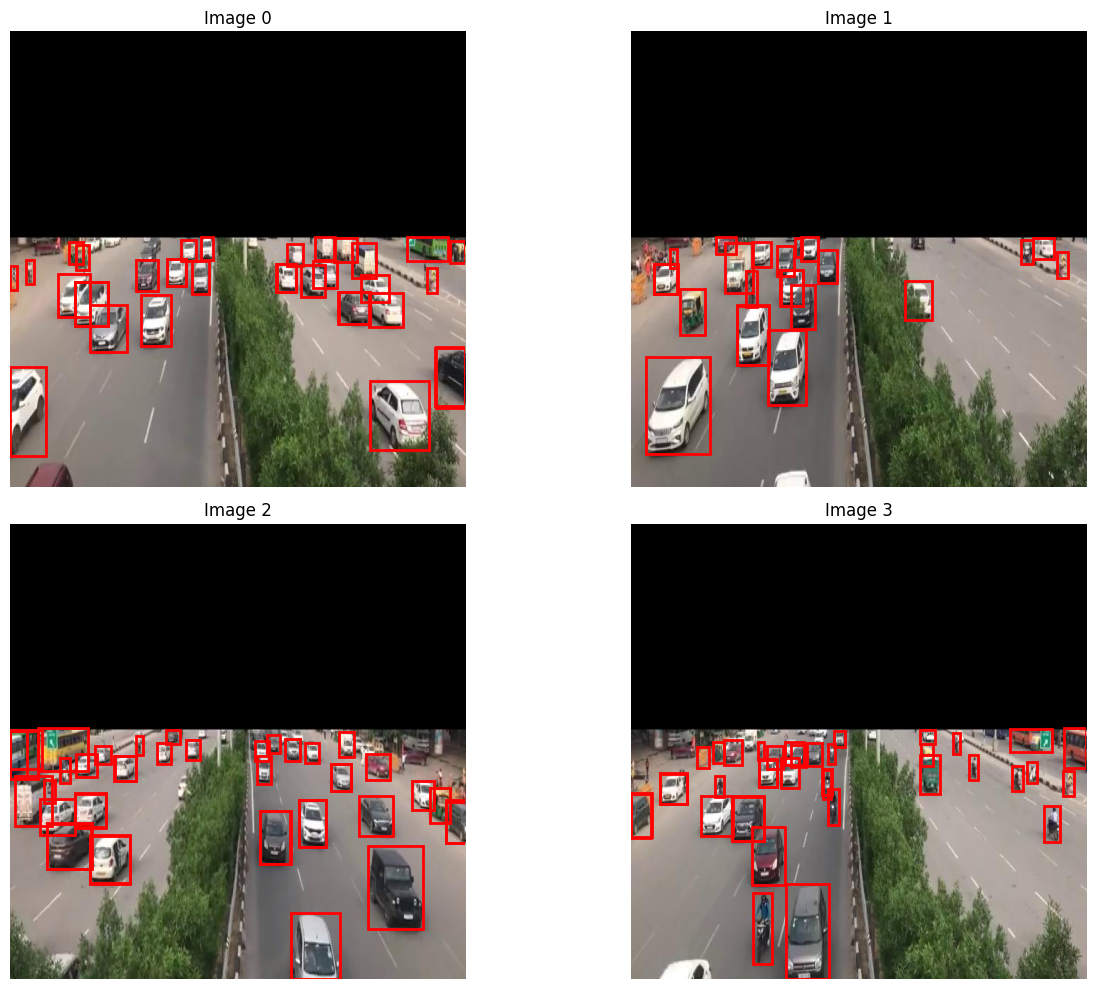

In [16]:
image_ids = coco.getImgIds()[:4]

plt.figure(figsize=(14, 10))

for i, image_id in enumerate(image_ids):

    image_info = coco.loadImgs(image_id)[0]

    image_path = os.path.join(
        "/content/traffic_dataset/images",
        image_info['file_name']
    )

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    annotations = coco.loadAnns(
        coco.getAnnIds(imgIds=[image_id])
    )

    plt.subplot(2, 2, i + 1)
    plt.imshow(image)

    for ann in annotations:
        x, y, w, h = ann['bbox']

        plt.gca().add_patch(
            plt.Rectangle(
                (x, y), w, h,
                fill=False,
                edgecolor='red',
                linewidth=2
            )
        )

    plt.title("Image " + str(image_id))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:
print("========== DATASET SUMMARY ==========")

print("Total Images:", len(coco.getImgIds()))

print("Total Categories:", len(categories))

print("Total Annotations:", len(coco.getAnnIds()))

print("\nCategories Found:")

for category in categories:
    print("-", category['name'])

print("\nDataset Exploration Completed Successfully!")

========== DATASET SUMMARY ==========
Total Images: 531
Total Categories: 12
Total Annotations: 18264

Categories Found:
- objects
- 2-Wheeler
- 3-Wheeler
- Bus
- Hatchback
- LCV
- MUV
- SUV
- Sedan
- T- Traveller -Tempo-traveller-
- Truck
- Van

Dataset Exploration Completed Successfully!
